<a href="https://colab.research.google.com/github/rybak97/free_courses/blob/main/Swarm_Intelligence_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Based on: https://machinelearningmastery.com/a-gentle-introduction-to-particle-swarm-optimization


In [41]:
import random
import numpy as np
import matplotlib.pyplot as plt

```markdown
## New Complicated Objective Function
We define the requested function:
$$f(x, y) = (x - 3.14)^2 + (y - 2.72)^2 + \sin(3x + 1.41) + \sin(4y - 1.73)$$
```

In [42]:
def complex_objective_function(coords):
    x, y = coords[0], coords[1]
    term1 = (x - 3.14)**2
    term2 = (y - 2.72)**2
    term3 = np.sin(3 * x + 1.41)
    term4 = np.sin(4 * y - 1.73)
    return term1 + term2 + term3 + term4

```markdown
## Defining the Particle Class
Each particle maintains its current position, velocity, personal best position, and personal best score.
```

In [43]:
class Particle:
    def __init__(self, bounds):
        self.position = np.array([random.uniform(bounds[i][0], bounds[i][1]) for i in range(len(bounds))])
        self.velocity = np.array([random.uniform(-1, 1) for _ in range(len(bounds))])
        self.best_position = np.copy(self.position)
        self.best_score = float('inf')

    def update_position(self, bounds):
        self.position = self.position + self.velocity

        # Keep particle within bounds
        for i in range(len(bounds)):
            if self.position[i] < bounds[i][0]:
                self.position[i] = bounds[i][0]
            if self.position[i] > bounds[i][1]:
                self.position[i] = bounds[i][1]

```markdown
## Implementing the PSO Algorithm
We iterate through a fixed number of generations to update each particle's velocity and position, leading the swarm to converge on the global minimum.
```

In [44]:
def pso(objective_func, bounds, num_particles=30, max_iter=100, w=0.5, c1=1.5, c2=1.5):
    # Initialize swarm
    swarm = [Particle(bounds) for _ in range(num_particles)]

    # Track global best
    global_best_position = None
    global_best_score = float('inf')

    # History list for plotting progress
    history = []

    for t in range(max_iter):
        for particle in swarm:
            # Evaluate fitness
            score = objective_func(particle.position)

            # Update personal best
            if score < particle.best_score:
                particle.best_score = score
                particle.best_position = np.copy(particle.position)

            # Update global best
            if score < global_best_score:
                global_best_score = score
                global_best_position = np.copy(particle.position)

        # Update velocities and positions
        for particle in swarm:
            r1, r2 = random.random(), random.random()
            cognitive_velocity = c1 * r1 * (particle.best_position - particle.position)
            social_velocity = c2 * r2 * (global_best_position - particle.position)
            particle.velocity = w * particle.velocity + cognitive_velocity + social_velocity
            particle.update_position(bounds)

        history.append(global_best_score)
        if t % 10 == 0 or t == max_iter - 1:
            print(f"Iteration {t:03d}: Best Score = {global_best_score:.6f}")

    return global_best_position, global_best_score, history

```markdown
## Updated PSO Algorithm with E-Notation
This implementation uses scientific representation (`{global_best_score:.6e}`) to display highly precise values at each step.
```

In [45]:
def pso_precision(objective_func, bounds, num_particles=30, max_iter=100, w=0.5, c1=1.5, c2=1.5):
    swarm = [Particle(bounds) for _ in range(num_particles)]
    global_best_position = None
    global_best_score = float('inf')
    history = []

    for t in range(max_iter):
        for particle in swarm:
            score = objective_func(particle.position)
            if score < particle.best_score:
                particle.best_score = score
                particle.best_position = np.copy(particle.position)

            if score < global_best_score:
                global_best_score = score
                global_best_position = np.copy(particle.position)

        for particle in swarm:
            r1, r2 = random.random(), random.random()
            cognitive_velocity = c1 * r1 * (particle.best_position - particle.position)
            social_velocity = c2 * r2 * (global_best_position - particle.position)
            particle.velocity = w * particle.velocity + cognitive_velocity + social_velocity
            particle.update_position(bounds)

        history.append(global_best_score)
        if t % 10 == 0 or t == max_iter - 1:
            print(f"Iteration {t:03d}: Best Score = {global_best_score:.6e}")

    return global_best_position, global_best_score, history

```markdown
## Run the Optimizer
Let's run the PSO algorithm on a 3-dimensional sphere function and plot the results.
```

```markdown
## Run Optimization and Plot 3D Visualization
Now, we run the updated PSO on the complex 2D function and display the convergence trajectory along with an interactive 3D surface plot.
```

Iteration 000: Best Score = -1.125999e+00
Iteration 010: Best Score = -1.808297e+00
Iteration 020: Best Score = -1.808350e+00
Iteration 024: Best Score = -1.808352e+00

Optimized Position (x, y): [3.1850953  3.12983075]
Optimized Score: -1.8083520091862317e+00


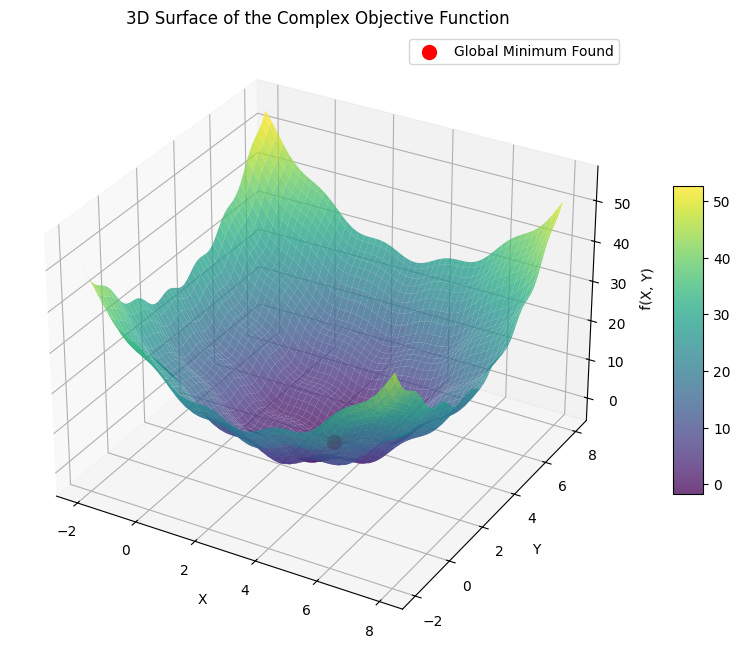

In [46]:
# Define 2D bounds around our expected optimum
complex_bounds = [(-2, 8), (-2, 8)]

# Run the optimization with fewer iterations (25 instead of 100)
best_pos, best_score, history = pso_precision(complex_objective_function, complex_bounds, num_particles=50, max_iter=25)

print(f"\nOptimized Position (x, y): {best_pos}")
print(f"Optimized Score: {best_score:.16e}")

# Create the 3D Plot
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

x_vals = np.linspace(-2, 8, 100)
y_vals = np.linspace(-2, 8, 100)
X, Y = np.meshgrid(x_vals, y_vals)
Z = (X - 3.14)**2 + (Y - 2.72)**2 + np.sin(3 * X + 1.41) + np.sin(4 * Y - 1.73)

# Plot surface
surf = ax.plot_surface(X, Y, Z, cmap='viridis', alpha=0.75, edgecolor='none')
# Plot best position found
ax.scatter(best_pos[0], best_pos[1], best_score, color='red', s=100, label='Global Minimum Found', depthshade=False)

ax.set_title('3D Surface of the Complex Objective Function')
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('f(X, Y)')
ax.legend()
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.show()

```markdown
## Artificial Bee Colony (ABC) Optimization
The Artificial Bee Colony algorithm simulates the foraging behavior of honey bees. It classifies bees into Employed, Onlooker, and Scout bees to find global minima.
```

In [47]:
def abc_optimization(objective_func, bounds, num_bees=50, max_iter=100):
    # Parameters
    dim = len(bounds)
    colony_size = num_bees
    employed_bees = colony_size // 2
    onlooker_bees = colony_size // 2
    limit = (colony_size * dim) // 2  # Limit for abandoning a food source

    # Initialize food sources (positions)
    foods = np.zeros((employed_bees, dim))
    fitness = np.zeros(employed_bees)
    trial = np.zeros(employed_bees)

    for i in range(employed_bees):
        foods[i] = np.array([random.uniform(bounds[d][0], bounds[d][1]) for d in range(dim)])
        obj_val = objective_func(foods[i])
        fitness[i] = 1.0 / (1.0 + obj_val) if obj_val >= 0 else 1.0 + abs(obj_val)

    best_index = np.argmax(fitness)
    global_best_pos = np.copy(foods[best_index])
    global_best_score = objective_func(global_best_pos)

    abc_history = []

    for cycle in range(max_iter):
        # 1. Employed Bees Phase
        for i in range(employed_bees):
            k = random.choice([x for x in range(employed_bees) if x != i])
            param_to_change = random.randint(0, dim - 1)
            phi = random.uniform(-1, 1)

            new_solution = np.copy(foods[i])
            new_solution[param_to_change] = foods[i][param_to_change] + phi * (foods[i][param_to_change] - foods[k][param_to_change])
            new_solution[param_to_change] = np.clip(new_solution[param_to_change], bounds[param_to_change][0], bounds[param_to_change][1])

            new_obj = objective_func(new_solution)
            new_fit = 1.0 / (1.0 + new_obj) if new_obj >= 0 else 1.0 + abs(new_obj)

            if new_fit > fitness[i]:
                foods[i] = new_solution
                fitness[i] = new_fit
                trial[i] = 0
            else:
                trial[i] += 1

        # 2. Onlooker Bees Phase
        prob = fitness / np.sum(fitness)
        for i in range(onlooker_bees):
            # Select source based on probability
            selected = np.random.choice(range(employed_bees), p=prob)
            k = random.choice([x for x in range(employed_bees) if x != selected])
            param_to_change = random.randint(0, dim - 1)
            phi = random.uniform(-1, 1)

            new_solution = np.copy(foods[selected])
            new_solution[param_to_change] = foods[selected][param_to_change] + phi * (foods[selected][param_to_change] - foods[k][param_to_change])
            new_solution[param_to_change] = np.clip(new_solution[param_to_change], bounds[param_to_change][0], bounds[param_to_change][1])

            new_obj = objective_func(new_solution)
            new_fit = 1.0 / (1.0 + new_obj) if new_obj >= 0 else 1.0 + abs(new_obj)

            if new_fit > fitness[selected]:
                foods[selected] = new_solution
                fitness[selected] = new_fit
                trial[selected] = 0
            else:
                trial[selected] += 1

        # Keep track of the absolute best solution
        for i in range(employed_bees):
            current_obj = objective_func(foods[i])
            if current_obj < global_best_score:
                global_best_score = current_obj
                global_best_pos = np.copy(foods[i])

        # 3. Scout Bee Phase
        abandoned = np.where(trial >= limit)[0]
        if len(abandoned) > 0:
            target = abandoned[0]
            foods[target] = np.array([random.uniform(bounds[d][0], bounds[d][1]) for d in range(dim)])
            obj_val = objective_func(foods[target])
            fitness[target] = 1.0 / (1.0 + obj_val) if obj_val >= 0 else 1.0 + abs(obj_val)
            trial[target] = 0

        abc_history.append(global_best_score)
        if cycle % 10 == 0 or cycle == max_iter - 1:
            print(f"ABC Cycle {cycle:03d}: Best Score = {global_best_score:.6e}")

    return global_best_pos, global_best_score, abc_history

```markdown
## Ant Colony Optimization for Continuous Domains ($ACO_{\mathbb{R}}$)
Continuous ACO models the pheromone distribution as probability density functions (commonly Gaussian) over the search space, allowing ants to sample promising regions.
```

In [48]:
def aco_continuous(objective_func, bounds, num_ants=30, archive_size=50, max_iter=100, q=0.1, xi=0.85):
    dim = len(bounds)

    # Initialize archive with random solutions
    archive_pos = np.zeros((archive_size, dim))
    archive_scores = np.zeros(archive_size)

    for i in range(archive_size):
        archive_pos[i] = np.array([random.uniform(bounds[d][0], bounds[d][1]) for d in range(dim)])
        archive_scores[i] = objective_func(archive_pos[i])

    # Sort archive based on performance
    indices = np.argsort(archive_scores)
    archive_pos = archive_pos[indices]
    archive_scores = archive_scores[indices]

    aco_history = []

    # Weights computation based on solution ranks
    ranks = np.arange(1, archive_size + 1)
    weights = 1.0 / (q * archive_size * np.sqrt(2 * np.pi)) * np.exp(-((ranks - 1) ** 2) / (2 * (q * archive_size) ** 2))
    probabilities = weights / np.sum(weights)

    for t in range(max_iter):
        new_solutions = np.zeros((num_ants, dim))

        for ant in range(num_ants):
            # Select a solution from the archive using probability distribution
            chosen_idx = np.random.choice(range(archive_size), p=probabilities)

            for d in range(dim):
                # Calculate distance standard deviation for variance
                mean_val = archive_pos[chosen_idx, d]
                sum_dist = np.sum(np.abs(archive_pos[:, d] - mean_val))
                std_val = xi * (sum_dist / (archive_size - 1))

                # Sample new coordinate
                new_solutions[ant, d] = np.random.normal(mean_val, std_val)
                new_solutions[ant, d] = np.clip(new_solutions[ant, d], bounds[d][0], bounds[d][1])

        # Update the archive
        for ant in range(num_ants):
            score = objective_func(new_solutions[ant])
            # Put solution into archive
            archive_pos = np.vstack([archive_pos, new_solutions[ant]])
            archive_scores = np.append(archive_scores, score)

        # Re-sort and keep only the top `archive_size` solutions
        sort_idx = np.argsort(archive_scores)
        archive_pos = archive_pos[sort_idx][:archive_size]
        archive_scores = archive_scores[sort_idx][:archive_size]

        best_score = archive_scores[0]
        aco_history.append(best_score)

        if t % 10 == 0 or t == max_iter - 1:
            print(f"ACO Iteration {t:03d}: Best Score = {best_score:.6e}")

    return archive_pos[0], archive_scores[0], aco_history

```markdown
## Run Comparison of ABC, ACO, and PSO
Let's run the new ABC and ACO algorithms, and compare their paths to the global minimum found by PSO.
```

=== Running ABC ===
ABC Cycle 000: Best Score = -1.309237e+00
ABC Cycle 010: Best Score = -1.807743e+00
ABC Cycle 020: Best Score = -1.808352e+00
ABC Cycle 024: Best Score = -1.808352e+00

=== Running ACO ===
ACO Iteration 000: Best Score = -1.578508e+00
ACO Iteration 010: Best Score = -1.808333e+00
ACO Iteration 020: Best Score = -1.808352e+00
ACO Iteration 024: Best Score = -1.808352e+00

Summary of Results:
PSO Minimum Found: -1.8083520091862317e+00 at [3.1850953  3.12983075]
ABC Minimum Found: -1.8083519863948512e+00 at [3.18510062 3.12974166]
ACO Minimum Found: -1.8083520303973986e+00 at [3.18514737 3.12982703]


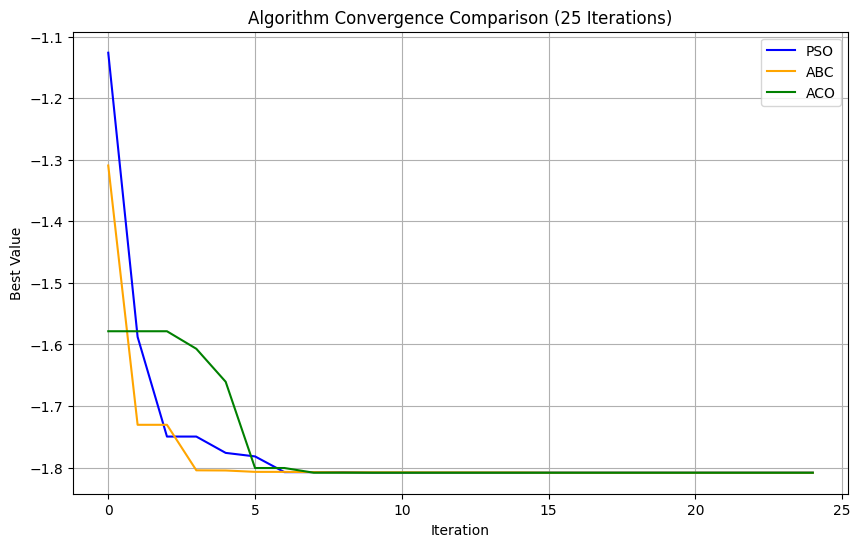

In [50]:
# Run ABC with reduced iterations (25 instead of 100)
print("=== Running ABC ===")
abc_pos, abc_best_score, abc_hist = abc_optimization(complex_objective_function, complex_bounds, num_bees=50, max_iter=25)

# Run ACO with reduced iterations (25 instead of 100)
print("\n=== Running ACO ===")
aco_pos, aco_best_score, aco_hist = aco_continuous(complex_objective_function, complex_bounds, num_ants=30, max_iter=25)

# Quick performance recap
print(f"\nSummary of Results:")
print(f"PSO Minimum Found: {best_score:.16e} at {best_pos}")
print(f"ABC Minimum Found: {abc_best_score:.16e} at {abc_pos}")
print(f"ACO Minimum Found: {aco_best_score:.16e} at {aco_pos}")

# Comparative Plot
plt.figure(figsize=(10, 6))
plt.plot(history, label='PSO', color='blue')
plt.plot(abc_hist, label='ABC', color='orange')
plt.plot(aco_hist, label='ACO', color='green')
plt.xlabel('Iteration')
plt.ylabel('Best Value')
plt.title('Algorithm Convergence Comparison (25 Iterations)')
plt.grid(True)
plt.legend()
plt.show()